#  NYC Expense Budget (Miscellaneous Agency 098) —

---
##  1: Mount Google Drive & Locate Dataset


In [1]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Target directory in Google Drive
DRIVE_PROJECT_DIR = '/content/drive/MyDrive/google_colab_project'

# Auto-detect folder location if moved
FILE_NAME = 'Expense_Budget--Miscellaneous_Expense_by_Category.csv'
if not os.path.exists(DRIVE_PROJECT_DIR):
    print("Searching for dataset across Google Drive...")
    for root, dirs, files in os.walk('/content/drive/MyDrive'):
        if FILE_NAME in files:
            DRIVE_PROJECT_DIR = root
            print(f"✅ Found dataset folder at: {DRIVE_PROJECT_DIR}")
            break
else:
    print(f"✅ Drive mounted successfully! Working folder: {DRIVE_PROJECT_DIR}")

RAW_FILE_PATH = os.path.join(DRIVE_PROJECT_DIR, FILE_NAME)
CLEANED_FILE_PATH = os.path.join(DRIVE_PROJECT_DIR, 'Expense_Budget--Miscellaneous_Expense_by_Category_cleaned.csv')


Mounted at /content/drive
✅ Drive mounted successfully! Working folder: /content/drive/MyDrive/google_colab_project


---
##  2: Import Libraries & Configure Visuals


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting configurations
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("✅ Libraries loaded! Pandas version:", pd.__version__)


✅ Libraries loaded! Pandas version: 2.2.3


---
## 3: Load Raw Dataset from Google Drive


In [3]:
if os.path.exists(RAW_FILE_PATH):
    df_raw = pd.read_csv(RAW_FILE_PATH)
    print(f"✅ Loaded raw dataset: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
    display(df_raw.head())
else:
    print(f"❌ Could not find {RAW_FILE_PATH}. Please verify your Google Drive path.")


✅ Loaded raw dataset: 283 rows, 10 columns


,PUBLICATION DATE,Fiscal Year,AGENCY CODE,AGENCY NAME,PS OTPS INDICATOR,CATEGORY NAME,SUBCATEGORY NAME,ADOPTED BUDGET AMOUNT,CURRENT MODIFIED BUDGET AMOUNT,FINANCIAL PLAN AMOUNT
0,20200630,2021,98,MISCELLANEOUS,P,Personal Services,NaN,1800684851,1010604730,1704955379
1,20200630,2021,98,MISCELLANEOUS,P,Fringe Benefits,Workers' Compensation,349296474,349296474,378396474
2,20200630,2021,98,MISCELLANEOUS,P,Fringe Benefits,Health Insurance Plans,4362494584,4326783234,1828823592
3,20200630,2021,98,MISCELLANEOUS,P,Fringe Benefits,Social Security Contributions,1209180475,1211055974,1183059972
4,20200630,2021,98,MISCELLANEOUS,P,Fringe Benefits,Unemployment Insurance Benefits,22053564,22053564,22953564


---
## 4: Data Quality Audit


In [5]:
print("=== DATASET INFORMATION ===")
df_raw.info()

print("\n=== MISSING VALUES PER COLUMN ===")
missing = df_raw.isnull().sum()
display(missing)

print("\n=== FISCAL YEARS COVERED ===")
print("Fiscal Years:", sorted(df_raw['Fiscal Year'].unique()))

print("\n=== CATEGORIES & NUMBER OF RECORDS ===")
print(df_raw['CATEGORY NAME'].value_counts())


=== DATASET INFORMATION ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 283 entries, 0 to 282
Data columns (total 10 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   PUBLICATION DATE                283 non-null    int64 
 1   Fiscal Year                     283 non-null    int64 
 2   AGENCY CODE                     283 non-null    int64 
 3   AGENCY NAME                     283 non-null    object
 4   PS OTPS INDICATOR               283 non-null    object
 5   CATEGORY NAME                   283 non-null    object
 6   SUBCATEGORY NAME                260 non-null    object
 7   ADOPTED BUDGET AMOUNT           283 non-null    int64 
 8   CURRENT MODIFIED BUDGET AMOUNT  283 non-null    int64 
 9   FINANCIAL PLAN AMOUNT           283 non-null    int64 
dtypes: int64(6), object(4)
memory usage: 22.2+ KB

=== MISSING VALUES PER COLUMN ===


,0
PUBLICATION DATE,0
Fiscal Year,0
AGENCY CODE,0
AGENCY NAME,0
PS OTPS INDICATOR,0
CATEGORY NAME,0
SUBCATEGORY NAME,23
ADOPTED BUDGET AMOUNT,0
CURRENT MODIFIED BUDGET AMOUNT,0
FINANCIAL PLAN AMOUNT,0



=== FISCAL YEARS COVERED ===
Fiscal Years: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]

=== CATEGORIES & NUMBER OF RECORDS ===
CATEGORY NAME
Other Than Personal Services    179
Fringe Benefits                  81
Personal Services                12
Indigent Defense Services        11
Name: count, dtype: int64


---
##  5: Data Cleaning & Normalization Pipeline


In [6]:
df_clean = df_raw.copy()

# 1. Standardize column names to snake_case
col_map = {
    'PUBLICATION DATE': 'publication_date',
    'Fiscal Year': 'fiscal_year',
    'AGENCY CODE': 'agency_code',
    'AGENCY NAME': 'agency_name',
    'PS OTPS INDICATOR': 'ps_otps_indicator',
    'CATEGORY NAME': 'category_name',
    'SUBCATEGORY NAME': 'subcategory_name',
    'ADOPTED BUDGET AMOUNT': 'adopted_budget_amount',
    'CURRENT MODIFIED BUDGET AMOUNT': 'current_modified_budget_amount',
    'FINANCIAL PLAN AMOUNT': 'financial_plan_amount'
}
df_clean = df_clean.rename(columns=col_map)

# 2. String cleanup (trim whitespaces)
for c in ['agency_name', 'ps_otps_indicator', 'category_name', 'subcategory_name']:
    df_clean[c] = df_clean[c].astype(str).str.strip()

# 3. Handle missing subcategories
df_clean['subcategory_name'] = df_clean.apply(
    lambda r: f"General {r['category_name']}" if r['subcategory_name'] in ['nan', 'None', '', 'NaN']
    else r['subcategory_name'],
    axis=1
)

# 4. Standardize Publication Date to YYYY-MM-DD
df_clean['publication_date_raw'] = df_clean['publication_date']
df_clean['publication_date'] = pd.to_datetime(df_clean['publication_date'].astype(str), format='%Y%m%d').dt.strftime('%Y-%m-%d')
df_clean['publication_year'] = pd.to_datetime(df_clean['publication_date']).dt.year
df_clean['publication_month'] = pd.to_datetime(df_clean['publication_date']).dt.month

# 5. Zero-pad agency code to 3 digits ('098')
df_clean['agency_code'] = df_clean['agency_code'].astype(str).str.zfill(3)

# 6. Add human-readable indicator
df_clean['ps_otps_description'] = df_clean['ps_otps_indicator'].map({
    'P': 'Personal Services (PS)',
    'O': 'Other Than Personal Services (OTPS)'
}).fillna(df_clean['ps_otps_indicator'])

# 7. Cast budget values to int64
for b in ['adopted_budget_amount', 'current_modified_budget_amount', 'financial_plan_amount']:
    df_clean[b] = pd.to_numeric(df_clean[b], errors='coerce').fillna(0).astype('int64')

# 8. Drop duplicates if any
df_clean = df_clean.drop_duplicates()

print(f"✅ Cleaning complete: {df_clean.shape[0]} rows ready.")
display(df_clean.head(3))


✅ Cleaning complete: 283 rows ready.


,publication_date,fiscal_year,agency_code,agency_name,ps_otps_indicator,category_name,subcategory_name,adopted_budget_amount,current_modified_budget_amount,financial_plan_amount,publication_date_raw,publication_year,publication_month,ps_otps_description
0,2020-06-30,2021,098,MISCELLANEOUS,P,Personal Services,General Personal Services,1800684851,1010604730,1704955379,20200630,2020,6,Personal Services (PS)
1,2020-06-30,2021,098,MISCELLANEOUS,P,Fringe Benefits,Workers' Compensation,349296474,349296474,378396474,20200630,2020,6,Personal Services (PS)
2,2020-06-30,2021,098,MISCELLANEOUS,P,Fringe Benefits,Health Insurance Plans,4362494584,4326783234,1828823592,20200630,2020,6,Personal Services (PS)


---
##  6: Feature Engineering (Budget Variances & Millions Scaling)


In [7]:
# 1. Budget modification variance (Modified - Adopted)
df_clean['modification_variance_usd'] = df_clean['current_modified_budget_amount'] - df_clean['adopted_budget_amount']

# 2. Percentage modification
df_clean['modification_pct_change'] = np.where(
    df_clean['adopted_budget_amount'] > 0,
    np.round(((df_clean['current_modified_budget_amount'] - df_clean['adopted_budget_amount']) / df_clean['adopted_budget_amount']) * 100, 2),
    0.0
)

# 3. Plan variances
df_clean['plan_vs_modified_variance_usd'] = df_clean['financial_plan_amount'] - df_clean['current_modified_budget_amount']
df_clean['plan_vs_adopted_variance_usd'] = df_clean['financial_plan_amount'] - df_clean['adopted_budget_amount']

# 4. Status classification
def classify_status(val):
    if val > 0:
        return 'Budget Increased'
    elif val < 0:
        return 'Budget Decreased'
    return 'Budget Unchanged'

df_clean['budget_modification_status'] = df_clean['modification_variance_usd'].apply(classify_status)

# 5. Amounts in Millions (USD)
df_clean['adopted_budget_millions'] = np.round(df_clean['adopted_budget_amount'] / 1e6, 2)
df_clean['current_modified_budget_millions'] = np.round(df_clean['current_modified_budget_amount'] / 1e6, 2)
df_clean['financial_plan_millions'] = np.round(df_clean['financial_plan_amount'] / 1e6, 2)
df_clean['modification_variance_millions'] = np.round(df_clean['modification_variance_usd'] / 1e6, 2)

print(f"✅ Feature engineering complete! Total columns: {df_clean.shape[1]}")
display(df_clean[['publication_date', 'fiscal_year', 'category_name', 'subcategory_name',
                  'adopted_budget_millions', 'current_modified_budget_millions', 'budget_modification_status']].head())


✅ Feature engineering complete! Total columns: 23


,publication_date,fiscal_year,category_name,subcategory_name,adopted_budget_millions,current_modified_budget_millions,budget_modification_status
0,2020-06-30,2021,Personal Services,General Personal Services,1800.68,1010.60,Budget Decreased
1,2020-06-30,2021,Fringe Benefits,Workers' Compensation,349.30,349.30,Budget Unchanged
2,2020-06-30,2021,Fringe Benefits,Health Insurance Plans,4362.49,4326.78,Budget Decreased
3,2020-06-30,2021,Fringe Benefits,Social Security Contributions,1209.18,1211.06,Budget Increased
4,2020-06-30,2021,Fringe Benefits,Unemployment Insurance Benefits,22.05,22.05,Budget Unchanged


---
## 7: Budget Analytics & Visualizations


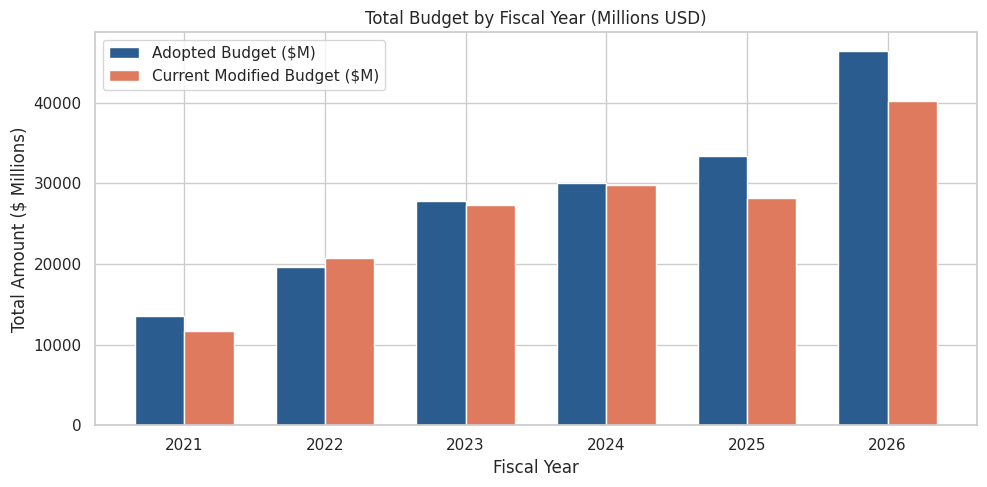

/tmp/ipykernel_3436/640141531.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_subcategories.values, y=top_subcategories.index, palette='crest')


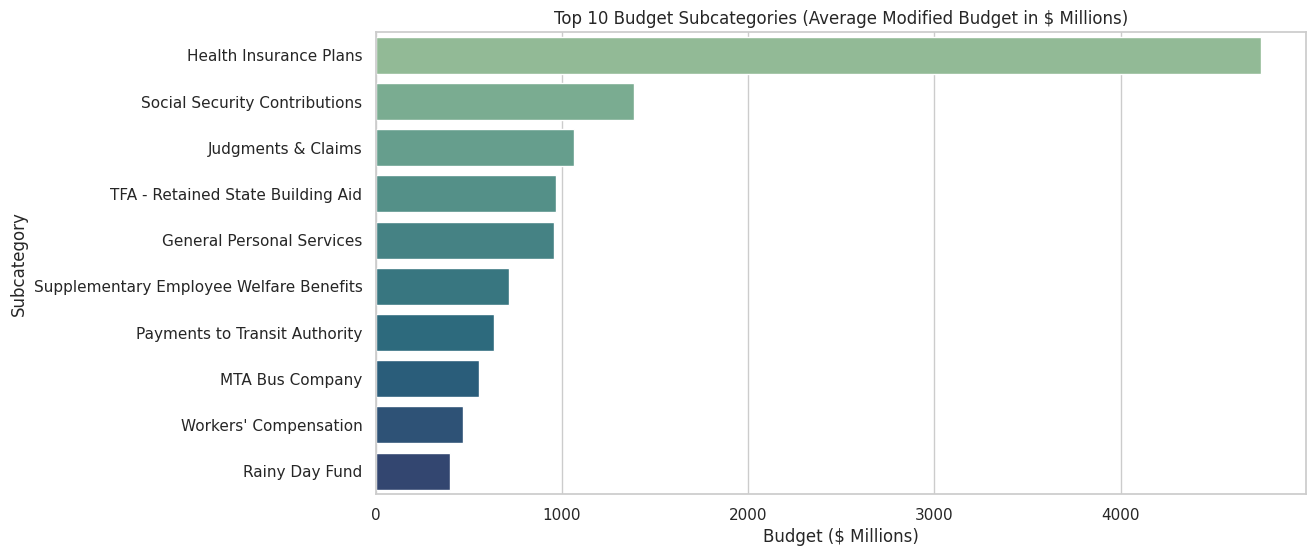

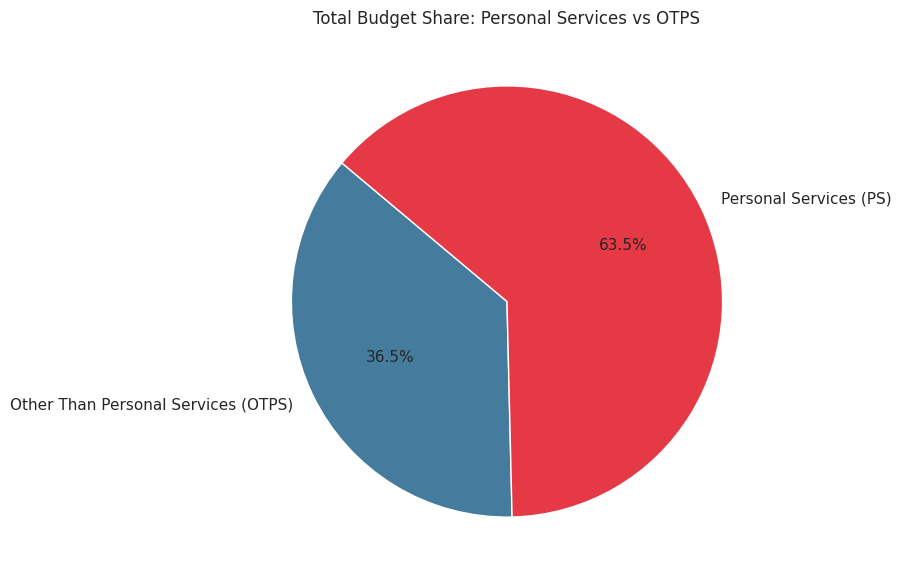

/tmp/ipykernel_3436/640141531.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=status_counts.index, y=status_counts.values, palette='Set2')


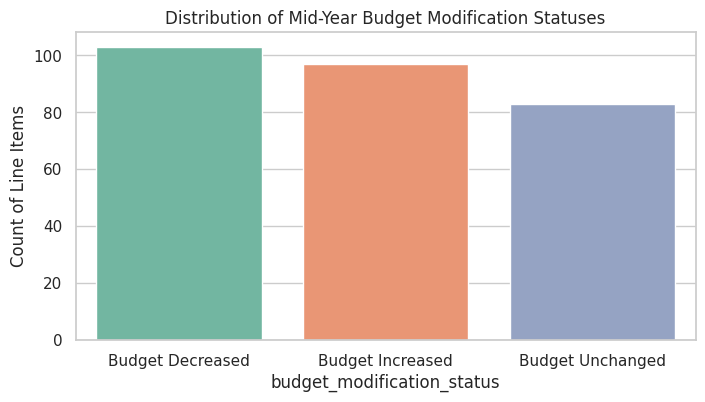

In [8]:
# 1. Budget by Fiscal Year (Adopted vs Modified)
yearly_budget = df_clean.groupby('fiscal_year')[['adopted_budget_millions', 'current_modified_budget_millions']].sum().reset_index()

plt.figure(figsize=(10, 5))
bar_width = 0.35
x = np.arange(len(yearly_budget))
plt.bar(x - bar_width/2, yearly_budget['adopted_budget_millions'], width=bar_width, label='Adopted Budget ($M)', color='#2b5c8f')
plt.bar(x + bar_width/2, yearly_budget['current_modified_budget_millions'], width=bar_width, label='Current Modified Budget ($M)', color='#e07a5f')
plt.xticks(x, yearly_budget['fiscal_year'])
plt.title("Total Budget by Fiscal Year (Millions USD)")
plt.xlabel("Fiscal Year")
plt.ylabel("Total Amount ($ Millions)")
plt.legend()
plt.tight_layout()
plt.show()

# 2. Top 10 Highest Funded Subcategories (Latest Modified Budget)
top_subcategories = df_clean.groupby('subcategory_name')['current_modified_budget_millions'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_subcategories.values, y=top_subcategories.index, palette='crest')
plt.title("Top 10 Budget Subcategories (Average Modified Budget in $ Millions)")
plt.xlabel("Budget ($ Millions)")
plt.ylabel("Subcategory")
plt.show()

# 3. PS vs OTPS Distribution
ps_otps_totals = df_clean.groupby('ps_otps_description')['current_modified_budget_millions'].sum()

plt.figure(figsize=(7, 7))
plt.pie(ps_otps_totals, labels=ps_otps_totals.index, autopct='%1.1f%%', colors=['#457b9d', '#e63946'], startangle=140)
plt.title("Total Budget Share: Personal Services vs OTPS")
plt.show()

# 4. Budget Modification Status Distribution
plt.figure(figsize=(8, 4))
status_counts = df_clean['budget_modification_status'].value_counts()
sns.barplot(x=status_counts.index, y=status_counts.values, palette='Set2')
plt.title("Distribution of Mid-Year Budget Modification Statuses")
plt.ylabel("Count of Line Items")
plt.show()


---
##  8: Save Cleaned Dataset to Google Drive & Direct Download


In [10]:
# Save directly to Google Drive
df_clean.to_csv(CLEANED_FILE_PATH, index=False)
print(f"🎉 Cleaned dataset saved to Google Drive at:")
print(f"👉 {CLEANED_FILE_PATH}")

# Optional direct download
try:
    from google.colab import files
    print("\nClicking below will also download the cleaned file to your local machine:")
    files.download(CLEANED_FILE_PATH)
except Exception as e:
    print(f"Direct browser download skipped ({e}). File is stored safely in Google Drive.")

🎉 Cleaned dataset saved to Google Drive at:
👉 /content/drive/MyDrive/google_colab_project/Expense_Budget--Miscellaneous_Expense_by_Category_cleaned.csv

Clicking below will also download the cleaned file to your local machine:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>